In [24]:
import os
import matplotlib.pyplot as plt
import pytorch_lightning as pl
import torch
from torch.utils.data import DataLoader
from matplotlib import pyplot as plt
from dataset import SegmentationDataset
from model import LeafModel
from torchvision.transforms import v2
from pytorch_lightning.loggers import MLFlowLogger
from pytorch_lightning.callbacks.early_stopping import EarlyStopping
from pytorch_lightning.callbacks import ModelCheckpoint
import shutil
import tempfile
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Create datasets and dataloaders

In [2]:
# We have to resize the images and masks to a fixed size for batching

transforms = v2.Compose([
    v2.Resize((256, 256), interpolation=v2.InterpolationMode.NEAREST),
])

train_dataset = SegmentationDataset(root_dir='roboflow/train/', transform=transforms, target_transform=transforms)
val_dataset = SegmentationDataset(root_dir='roboflow/valid/', transform=transforms, target_transform=transforms)
test_dataset = SegmentationDataset(root_dir='roboflow/test/', transform=transforms, target_transform=transforms)

print(f'Train samples: {len(train_dataset)}')
print(f'Validation samples: {len(val_dataset)}')
print(f'Test samples: {len(test_dataset)}')

n_cpu = os.cpu_count() or 8
train_dataloader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=n_cpu - 2)
valid_dataloader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=n_cpu - 2)
test_dataloader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=n_cpu - 2)

loading annotations into memory...
Done (t=0.12s)
creating index...
index created!
Filtered out 15 images with empty masks from roboflow/train/
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Filtered out 3 images with empty masks from roboflow/valid/
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Train samples: 683
Validation samples: 196
Test samples: 100


Visualize a few samples from the dataset to ensure that images and masks are loaded correctly.

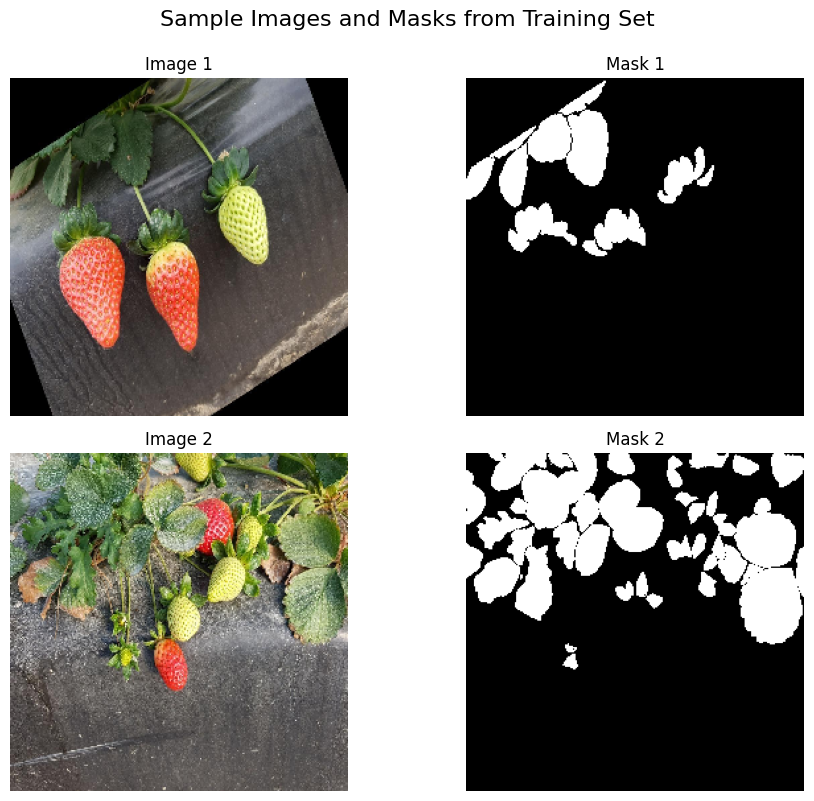

In [3]:
num_samples = 2

figure, axes = plt.subplots(num_samples, 2, figsize=(10, 4 * num_samples))
figure.suptitle('Sample Images and Masks from Training Set', fontsize=16, y=0.995)

for i in range(num_samples):
    img_id = torch.randint(0, len(train_dataset), (1,)).item()
    image, mask = train_dataset[img_id]
    
    # Display image
    axes[i, 0].imshow(image.permute(1, 2, 0))
    axes[i, 0].set_title(f'Image {i+1}')
    axes[i, 0].axis('off')
    
    # Display mask
    axes[i, 1].imshow(mask.squeeze(), cmap='gray')
    axes[i, 1].set_title(f'Mask {i+1}')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

Enable mlflow logging

In [25]:
# Create temporary directory for local artifacts
temp_dir = tempfile.mkdtemp()

mlflow_logger = MLFlowLogger(
    experiment_name="leaf_segmentation",
    tracking_uri="http://localhost:5011",
    log_model=True,
    save_dir=temp_dir,  # Temporary local storage
)

Configure model

In [26]:
EPOCHS = 300
T_MAX = EPOCHS * len(train_dataloader)
OUT_CLASSES = 1
model = LeafModel("FPN", "resnet34", in_channels=3, out_classes=1, t_max=T_MAX)

Set hyperparameters and start training loop

In [27]:
# Early stopping callback - monitors validation loss
early_stop_callback = EarlyStopping(
    monitor="val_loss",
    patience=3,
    mode="min",
    verbose=True
)

# Model checkpoint callback - only saves best model to MLflow
checkpoint_callback = ModelCheckpoint(
    dirpath=temp_dir,  # Temporary local storage
    filename="best-model",
    monitor="val_loss",
    mode="min",
    save_top_k=1,  # Only keep the best model
    save_last=False,  # Don't save the last model
)

trainer = pl.Trainer(
    max_epochs=EPOCHS,
    logger=mlflow_logger,
    callbacks=[early_stop_callback, checkpoint_callback],
    enable_checkpointing=True,
)

trainer.fit(
    model,
    train_dataloaders=train_dataloader,
    val_dataloaders=valid_dataloader,
)

# Clean up temporary directory after training
shutil.rmtree(temp_dir, ignore_errors=True)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
TPU available: False, using: 0 TPU cores


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]

  | Name    | Type     | Params | Mode 
---------------------------------------------
0 | model   | FPN      | 23.2 M | train
1 | loss_fn | DiceLoss | 0      | train
---------------------------------------------
23.2 M    Trainable params
0         Non-trainable params
23.2 M    Total params
92.622    Total estimated model params size (MB)
175       Modules in train mode
0         Modules in eval mode

  | Name    | Type     | Params | Mode 
---------------------------------------------
0 | model   | FPN      | 23.2 M | train
1 | loss_fn | DiceLoss | 0      | train
---------------------------------------------
23.2 M    Trainable params
0         Non-trainable params
23.2 M    Total params
92.622    Total estimated model params size (MB)
175       Modules in train mode
0         Modules in eval mode


Epoch 0: 100%|██████████| 22/22 [00:05<00:00,  3.76it/s, v_num=3fef, val_loss=0.307, valid_per_image_iou=0.482, valid_dataset_iou=0.530, valid_accuracy=0.876, valid_f1_score=0.693, train_loss=0.391]

Metric val_loss improved. New best score: 0.307


Epoch 1: 100%|██████████| 22/22 [00:07<00:00,  2.96it/s, v_num=3fef, val_loss=0.251, valid_per_image_iou=0.569, valid_dataset_iou=0.601, valid_accuracy=0.892, valid_f1_score=0.750, train_loss=0.284, train_per_image_iou=0.416, train_dataset_iou=0.403, train_accuracy=0.782, train_f1_score=0.574]

Metric val_loss improved by 0.056 >= min_delta = 0.0. New best score: 0.251


... (33 outputs left out)

Metric val_loss improved by 0.000 >= min_delta = 0.0. New best score: 0.141


Epoch 24: 100%|██████████| 22/22 [00:06<00:00,  3.14it/s, v_num=3fef, val_loss=0.142, valid_per_image_iou=0.744, valid_dataset_iou=0.753, valid_accuracy=0.946, valid_f1_score=0.859, train_loss=0.0788, train_per_image_iou=0.844, train_dataset_iou=0.857, train_accuracy=0.971, train_f1_score=0.923]

Monitored metric val_loss did not improve in the last 3 records. Best score: 0.141. Signaling Trainer to stop.


Epoch 24: 100%|██████████| 22/22 [00:07<00:00,  3.11it/s, v_num=3fef, val_loss=0.142, valid_per_image_iou=0.744, valid_dataset_iou=0.753, valid_accuracy=0.946, valid_f1_score=0.859, train_loss=0.0788, train_per_image_iou=0.844, train_dataset_iou=0.857, train_accuracy=0.971, train_f1_score=0.923]

🏃 View run rebellious-frog-769 at: http://localhost:5011/#/experiments/26/runs/38d104e3d98f4a8d8a7e64b82b263fef
🧪 View experiment at: http://localhost:5011/#/experiments/26
🏃 View run rebellious-frog-769 at: http://localhost:5011/#/experiments/26/runs/38d104e3d98f4a8d8a7e64b82b263fef
🧪 View experiment at: http://localhost:5011/#/experiments/26


Validation Metrics

In [28]:
valid_metrics = trainer.validate(model, dataloaders=valid_dataloader, verbose=False)
print(valid_metrics)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Validation DataLoader 0: 100%|██████████| 7/7 [00:00<00:00, 12.02it/s]

🏃 View run rebellious-frog-769 at: http://localhost:5011/#/experiments/26/runs/38d104e3d98f4a8d8a7e64b82b263fef
🧪 View experiment at: http://localhost:5011/#/experiments/26
[{'val_loss': 0.14164352416992188, 'valid_per_image_iou': 0.744105875492096, 'valid_dataset_iou': 0.7525409460067749, 'valid_accuracy': 0.9456894397735596, 'valid_f1_score': 0.8587998151779175}]
🏃 View run rebellious-frog-769 at: http://localhost:5011/#/experiments/26/runs/38d104e3d98f4a8d8a7e64b82b263fef
🧪 View experiment at: http://localhost:5011/#/experiments/26
[{'val_loss': 0.14164352416992188, 'valid_per_image_iou': 0.744105875492096, 'valid_dataset_iou': 0.7525409460067749, 'valid_accuracy': 0.9456894397735596, 'valid_f1_score': 0.8587998151779175}]


Visualize predictions

[W1128 14:43:53.055107334 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


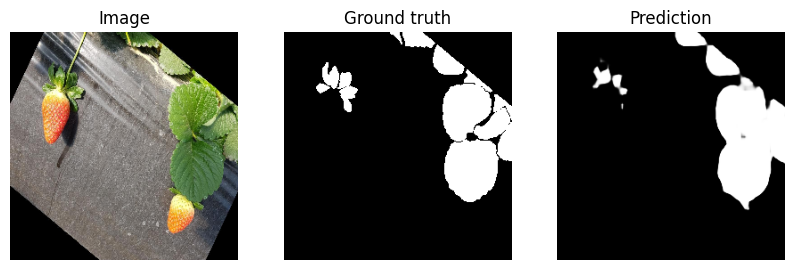

[W1128 14:43:54.268393024 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


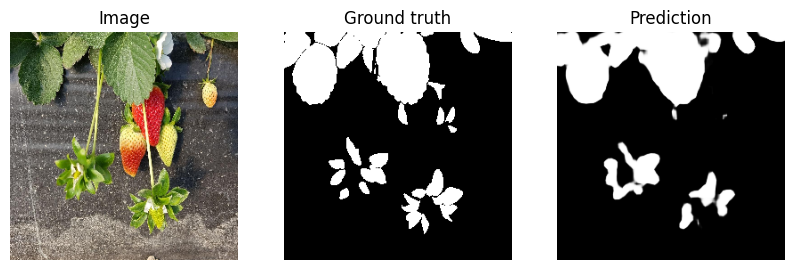

[W1128 14:43:54.490393888 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


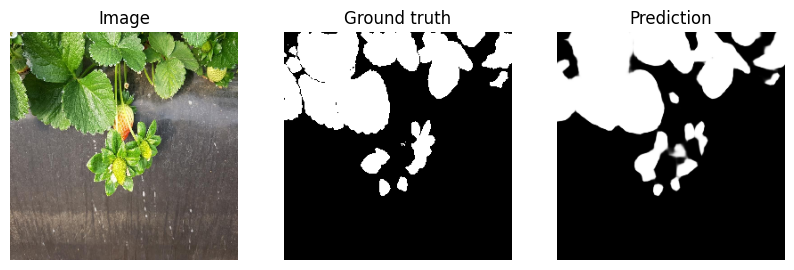

[W1128 14:43:54.705179862 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


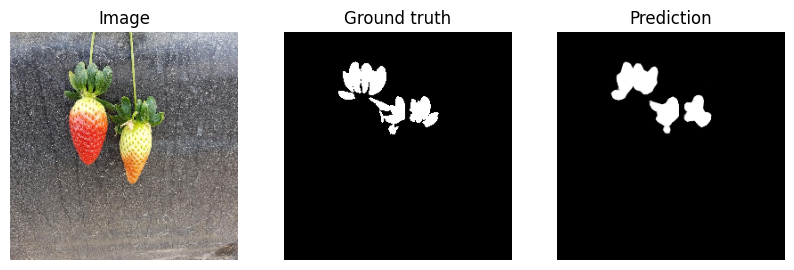

[W1128 14:43:54.926733796 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


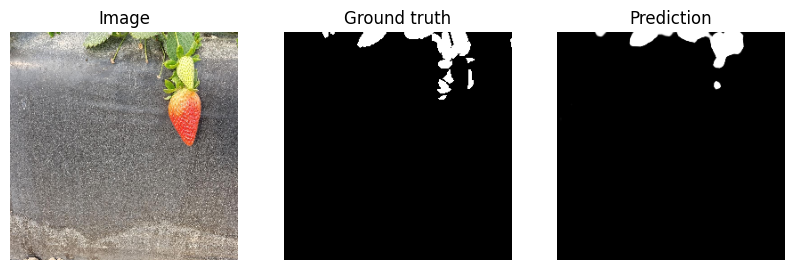

[W1128 14:43:55.317016844 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


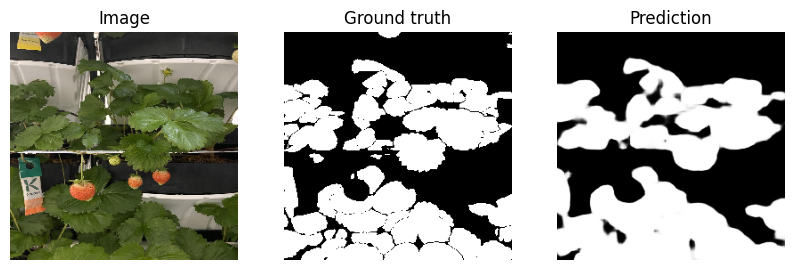

[W1128 14:43:55.533196882 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


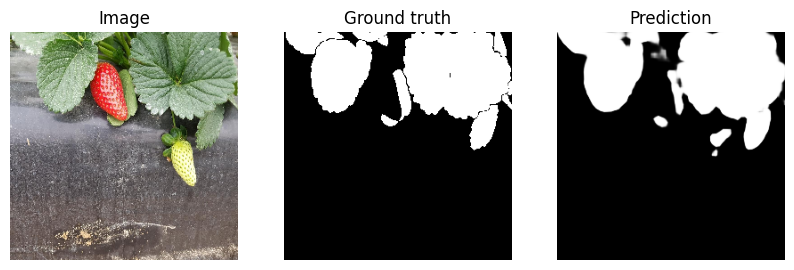

[W1128 14:43:55.755750043 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


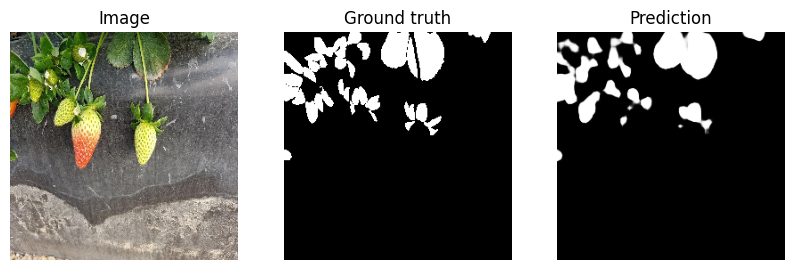

[W1128 14:43:55.052865287 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


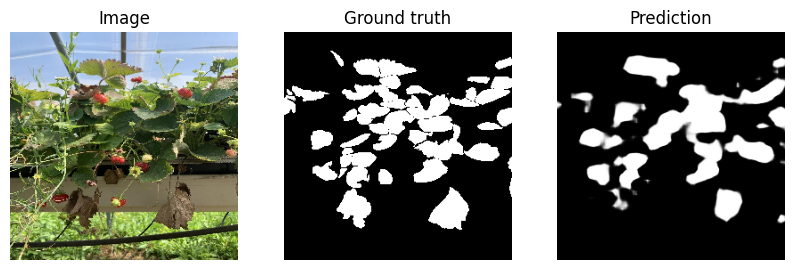

[W1128 14:43:56.382221057 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


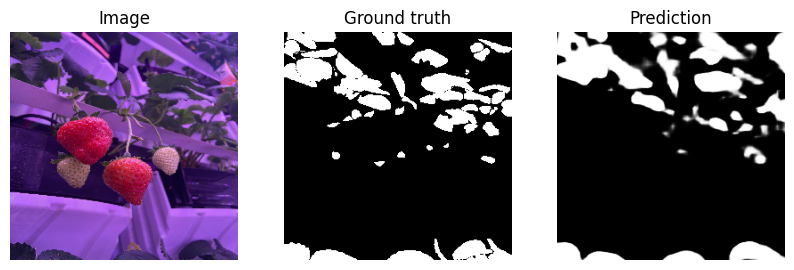

In [30]:
import random

num_samples = 10
# Get all test samples
all_samples = list(range(len(test_dataset)))
random_indices = random.sample(all_samples, min(num_samples, len(all_samples)))

for idx in random_indices:
    image, gt_mask = test_dataset[idx]
    
    with torch.inference_mode():
        model.eval()
        logits = model(image.unsqueeze(0))
    
    pr_mask = logits.sigmoid().squeeze()
    
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title("Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(gt_mask.squeeze(), cmap='gray')
    plt.title("Ground truth")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pr_mask.detach().numpy(), cmap='gray')
    plt.title("Prediction")
    plt.axis("off")
    plt.show()